# CMIP6 checkpoint: exploratory graphs + data export for the D3 prototype

Run top to bottom in Google Colab (Runtime > Run all). Takes roughly 5 to 15 minutes, mostly downloading.

Outputs:
- `figs/01..06_*.png` : the six exploratory graphs for the checkpoint video
- `cmip6_grid.json` : compact 5 degree, decadal dataset the D3 page loads (put it in the repo next to `index.html`)

In [3]:
pip install -q gcsfs "zarr<3" xarray cftime

Note: you may need to restart the kernel to use updated packages.


The system cannot find the path specified.
  You can safely remove it manually.


In [1]:
import os, json
import numpy as np, pandas as pd, xarray as xr, gcsfs
import matplotlib.pyplot as plt

os.makedirs('figs', exist_ok=True)
EXPS = ['historical', 'ssp126', 'ssp245', 'ssp585']
SCEN = ['ssp126', 'ssp245', 'ssp585']
SCEN_LABEL = {'ssp126': 'SSP1-2.6 (low emissions)', 'ssp245': 'SSP2-4.5 (middle)', 'ssp585': 'SSP5-8.5 (high emissions)'}
SCEN_COLOR = {'ssp126': '#173c66', 'ssp245': '#f79420', 'ssp585': '#951b1e'}
CANDIDATES = ['GFDL-ESM4', 'CESM2', 'MPI-ESM1-2-LR', 'IPSL-CM6A-LR', 'CanESM5']

catalog = pd.read_csv('https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv')
fs = gcsfs.GCSFileSystem(token='anon')

def pick(model, var):
    q = catalog[(catalog.source_id == model) & (catalog.table_id == 'Amon') &
                (catalog.variable_id == var) & (catalog.experiment_id.isin(EXPS))]
    if not all((q.experiment_id == e).any() for e in EXPS):
        return None
    common = set.intersection(*[set(q[q.experiment_id == e].member_id) for e in EXPS])
    if not common:
        return None
    member = 'r1i1p1f1' if 'r1i1p1f1' in common else sorted(common)[0]
    stores = {e: q[(q.experiment_id == e) & (q.member_id == member)].sort_values('version').zstore.iloc[-1] for e in EXPS}
    return member, stores

for MODEL in CANDIDATES:
    tas_pick, pr_pick = pick(MODEL, 'tas'), pick(MODEL, 'pr')
    if tas_pick and pr_pick:
        break
print('Model:', MODEL, '| tas member:', tas_pick[0], '| pr member:', pr_pick[0])

Model: GFDL-ESM4 | tas member: r1i1p1f1 | pr member: r1i1p1f1


In [5]:
# Target grid: 5 degree cells (36 x 72). Coarse on purpose: small enough for the browser.
TLAT = np.arange(-87.5, 90, 5.0)
TLON = np.arange(2.5, 360, 5.0)

def to_annual_grid(da):
    """Monthly field -> annual means on the 5 degree grid."""
    ren = {k: v for k, v in {'latitude': 'lat', 'longitude': 'lon'}.items() if k in da.dims}
    da = da.rename(ren)
    da = da.assign_coords(lon=(da.lon % 360)).sortby('lon')
    da = da.interp(lat=TLAT, lon=TLON)           # linear regrid to the coarse grid
    return da.groupby('time.year').mean('time')

def load_var(stores, var):
    out = {}
    for e, z in stores.items():
        ds = xr.open_zarr(fs.get_mapper(z), consolidated=True)
        out[e] = to_annual_grid(ds[var]).load()
        print('loaded', var, e, out[e].sizes)
    return out

tas = load_var(tas_pick[1], 'tas')
pr = load_var(pr_pick[1], 'pr')

loaded tas historical Frozen({'year': 165, 'lat': 36, 'lon': 72})
loaded tas ssp126 Frozen({'year': 86, 'lat': 36, 'lon': 72})
loaded tas ssp245 Frozen({'year': 86, 'lat': 36, 'lon': 72})
loaded tas ssp585 Frozen({'year': 86, 'lat': 36, 'lon': 72})
loaded pr historical Frozen({'year': 165, 'lat': 36, 'lon': 72})
loaded pr ssp126 Frozen({'year': 86, 'lat': 36, 'lon': 72})
loaded pr ssp245 Frozen({'year': 86, 'lat': 36, 'lon': 72})
loaded pr ssp585 Frozen({'year': 86, 'lat': 36, 'lon': 72})


In [6]:
def build(raw, scale=1.0):
    """Historical + each scenario joined into one 1850-2100 series per scenario."""
    hist = raw['historical'].sel(year=slice(1850, 2014)) * scale
    return {s: xr.concat([hist, raw[s].sel(year=slice(2015, 2100)) * scale], dim='year') for s in SCEN}

T = build(tas)              # Kelvin (anomalies are the same in C)
P = build(pr, 86400.0)      # kg m-2 s-1 -> mm/day

base_T = T['ssp585'].sel(year=slice(1850, 1900)).mean('year')   # pre-industrial baseline
base_P = P['ssp585'].sel(year=slice(1850, 1900)).mean('year')

dT = {s: T[s] - base_T for s in SCEN}                                   # warming, C
dP = {s: ((P[s] - base_P) / base_P * 100).clip(-100, 100) for s in SCEN}   # precip change, %, clipped

w = np.cos(np.deg2rad(TLAT))
def gmean(da):
    return da.weighted(xr.DataArray(w, coords={'lat': TLAT}, dims='lat')).mean(('lat', 'lon'))

def eoc(da):   # end of century mean
    return da.sel(year=slice(2081, 2100)).mean('year')

## Exploratory graphs

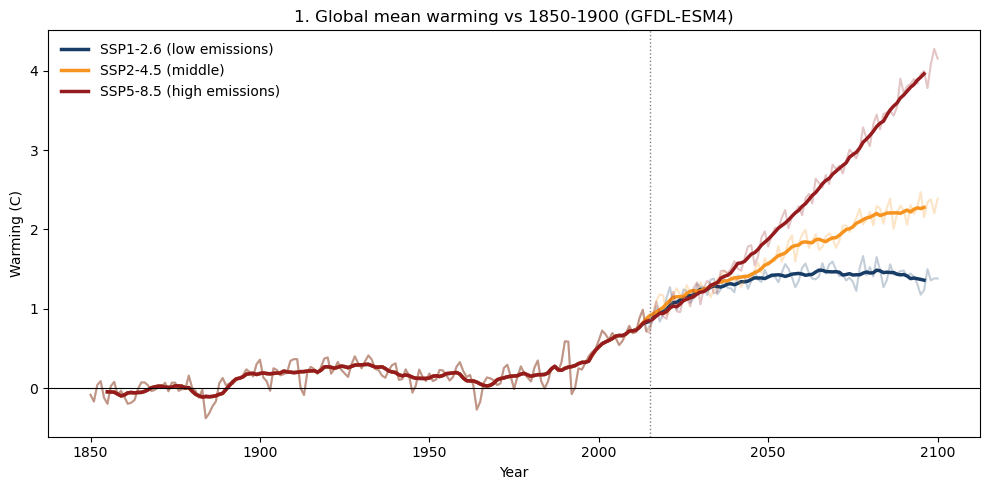

In [7]:
# 1. Global mean warming, 1850-2100, by scenario
fig, ax = plt.subplots(figsize=(10, 5))
for s in SCEN:
    g = gmean(dT[s])
    ax.plot(g.year, g, color=SCEN_COLOR[s], alpha=0.25)
    ax.plot(g.year, g.rolling(year=10, center=True).mean(), color=SCEN_COLOR[s], lw=2.5, label=SCEN_LABEL[s])
ax.axhline(0, color='k', lw=0.8); ax.axvline(2015, color='gray', ls=':', lw=1)
ax.set(title=f'1. Global mean warming vs 1850-1900 ({MODEL})', xlabel='Year', ylabel='Warming (C)')
ax.legend(frameon=False); plt.tight_layout(); plt.savefig('figs/01_global_mean.png', dpi=150); plt.show()

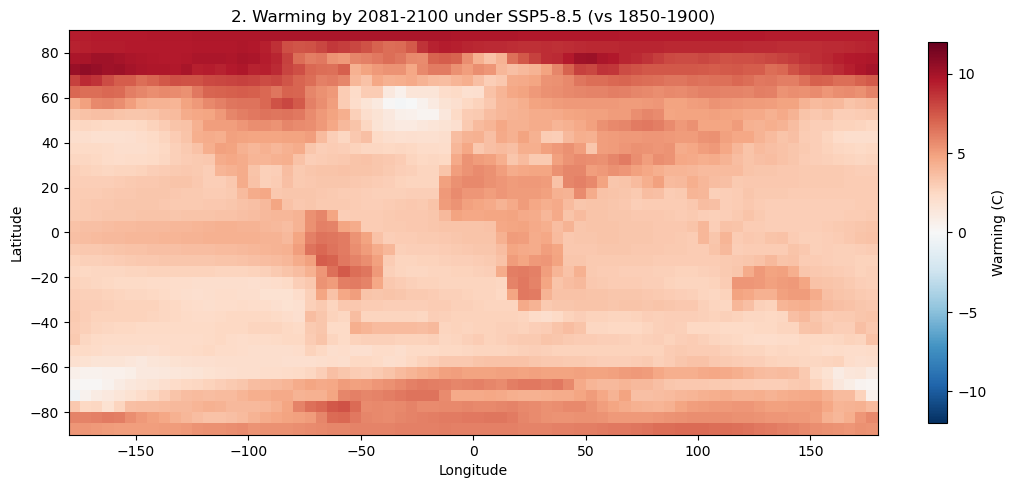

In [8]:
# 2. Where does it warm? End of century, high emissions
def map_plot(da, title, fname, cmap, vmin, vmax, label):
    fig, ax = plt.subplots(figsize=(11, 5))
    lon = np.where(TLON > 180, TLON - 360, TLON); order = np.argsort(lon)
    m = ax.pcolormesh(lon[order], TLAT, da.values[:, order], cmap=cmap, vmin=vmin, vmax=vmax, shading='nearest')
    plt.colorbar(m, ax=ax, label=label, shrink=0.85)
    ax.set(title=title, xlabel='Longitude', ylabel='Latitude'); ax.set_aspect('equal')
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

map_plot(eoc(dT['ssp585']), '2. Warming by 2081-2100 under SSP5-8.5 (vs 1850-1900)',
         'figs/02_map_ssp585.png', 'RdBu_r', -12, 12, 'Warming (C)')

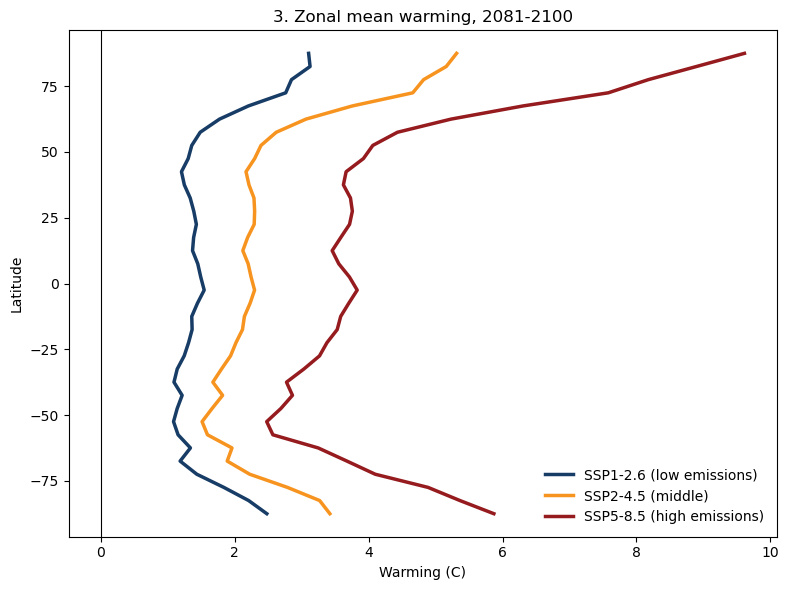

In [9]:
# 3. Warming by latitude: Arctic amplification
fig, ax = plt.subplots(figsize=(8, 6))
for s in SCEN:
    ax.plot(eoc(dT[s]).mean('lon'), TLAT, color=SCEN_COLOR[s], lw=2.5, label=SCEN_LABEL[s])
ax.axvline(0, color='k', lw=0.8)
ax.set(title='3. Zonal mean warming, 2081-2100', xlabel='Warming (C)', ylabel='Latitude')
ax.legend(frameon=False); plt.tight_layout(); plt.savefig('figs/03_zonal.png', dpi=150); plt.show()

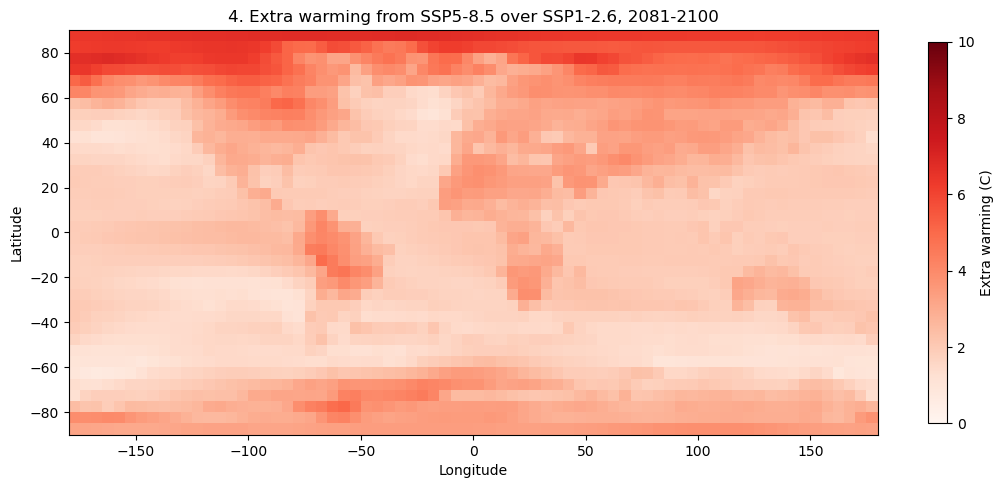

In [10]:
# 4. What the emissions path decides: high minus low scenario
map_plot(eoc(dT['ssp585']) - eoc(dT['ssp126']), '4. Extra warming from SSP5-8.5 over SSP1-2.6, 2081-2100',
         'figs/04_map_difference.png', 'Reds', 0, 10, 'Extra warming (C)')

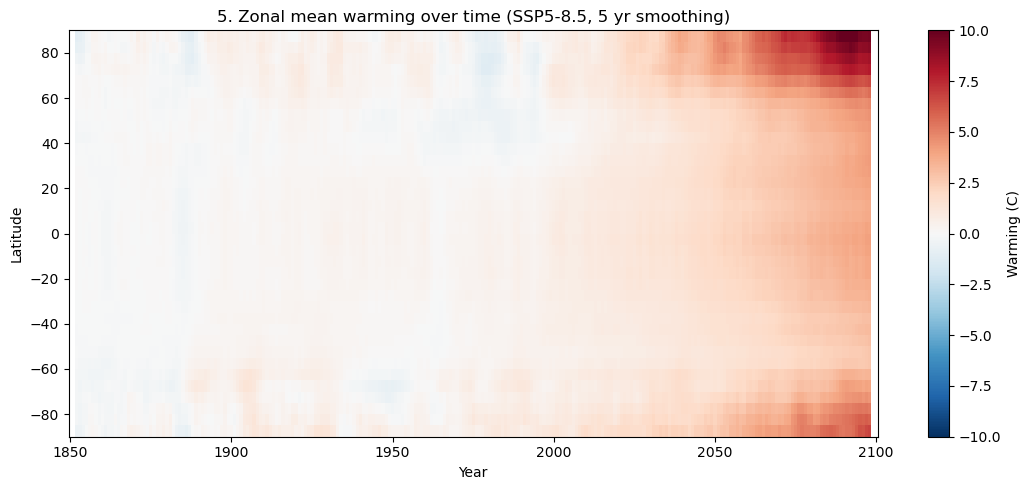

In [11]:
# 5. Hovmoller: latitude x time, high emissions
z = dT['ssp585'].mean('lon').rolling(year=5, center=True).mean()
fig, ax = plt.subplots(figsize=(11, 5))
m = ax.pcolormesh(z.year, TLAT, z.T, cmap='RdBu_r', vmin=-10, vmax=10, shading='nearest')
plt.colorbar(m, ax=ax, label='Warming (C)')
ax.set(title='5. Zonal mean warming over time (SSP5-8.5, 5 yr smoothing)', xlabel='Year', ylabel='Latitude')
plt.tight_layout(); plt.savefig('figs/05_hovmoller.png', dpi=150); plt.show()

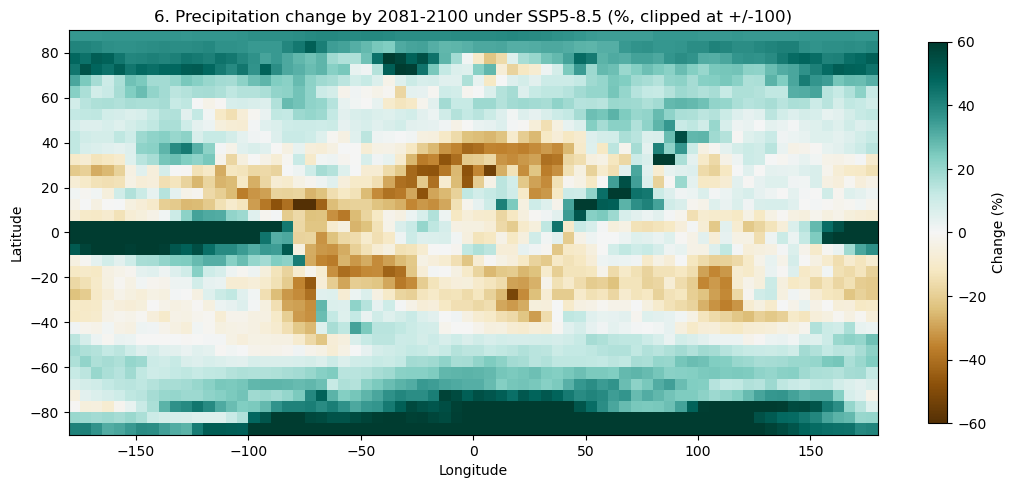

In [12]:
# 6. Precipitation change, end of century, high emissions
map_plot(eoc(dP['ssp585']), '6. Precipitation change by 2081-2100 under SSP5-8.5 (%, clipped at +/-100)',
         'figs/06_precip_ssp585.png', 'BrBG', -60, 60, 'Change (%)')

## Export for the D3 prototype

In [ ]:
DECADES = list(range(1850, 2100, 10))   # 1850s ... 2090s

def decadal(da):
    vals = [da.sel(year=slice(d, d + 9)).mean('year').values.ravel() for d in DECADES]   # row-major: lat, then lon
    return np.round(np.array(vals), 1)

def clean(a):
    return [[None if np.isnan(v) else float(v) for v in row] for row in a]

out = {
    'model': MODEL, 'member': tas_pick[0],
    'lats': TLAT.tolist(), 'lons': TLON.tolist(), 'decades': DECADES,
    'baseline': '1850-1900',
    'measures': {
        'tas': {s: clean(decadal(dT[s])) for s in SCEN},
        'pr': {s: clean(decadal(dP[s])) for s in SCEN},
    },
    'global': {
        'tas': {s: [round(float(gmean(dT[s].sel(year=slice(d, d + 9)).mean('year'))), 2) for d in DECADES] for s in SCEN},
        'pr': {s: [round(float(gmean(dP[s].sel(year=slice(d, d + 9)).mean('year'))), 2) for d in DECADES] for s in SCEN},
    },
}
with open('cmip6_grid.json', 'w') as f:
    json.dump(out, f, separators=(',', ':'))
print(f"cmip6_grid.json: {os.path.getsize('cmip6_grid.json') / 1e6:.1f} MB")

In [ ]:
# Download everything (Colab)
!zip -qr checkpoint_outputs.zip figs cmip6_grid.json
from google.colab import files
files.download('checkpoint_outputs.zip')